# LM1 Lab — Exponentials, Logarithms and Compounding

Companion notebook to **From Calculus to Kelly, LM1**. It rebuilds every exhibit and computational example in the module from verified price files, and solves the computational practice problems.

| Part | Rebuilds |
|:--|:--|
| 1 | Total-return series from raw closes, dividends and the split; the case (Exhibit 1) and the price/dividend split (Example 1) |
| 2 | Logarithms and log-scale charts (Exhibits 2–3) |
| 3 | Compounding frequency and the number $e$ (Exhibits 4–5, Examples 2–3) |
| 4 | Holding-period, annualized and continuously compounded returns (Exhibits 6–7, Examples 4–6) |
| 5 | Aggregation across time, positions and currencies (Exhibit 8, Examples 7–8) |
| 6 | Growth equations, doubling, drawdowns and recovery (Exhibits 9–12, Examples 9–10) |
| 7 | Practice-problem solutions and an extension exercise |

**Data.** `data/` holds a snapshot of FinMind `TaiwanStockPrice` closes for 0050 and 00631L (2014-10-31 → 2026-10-08) and 0050 cash dividends from `TaiwanStockDividendResult`, retrieved 2026-10-10. Every close was checked against FinMind's own `spread` column (close − previous close); the only mismatches are ex-dividend days and the two split days, which Part 1 handles explicitly. The folder is not in the repository (FinMind's licence forbids redistributing raw data): build it from the repository root with `python3 data/fetch_finmind.py` and `python3 data/make_lab_data.py` (needs `FINMIND_TOKEN`).

**Conventions (as in the module).** A span in years is $\tau=$ calendar days ÷ 365.25; NTD deposits accrue on an actual/365 basis. $T$ counts returns, and $A$ is the number of returns per year used to annualize, quoted from the sample in use. A drawdown $\mathrm{DD}=1-W/\text{running peak}$ is a positive number.

**Environment.** `uv pip install polars pyarrow numpy matplotlib`.

In [1]:
import math
from datetime import date
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

DATA = Path("data")
BASE = date(2014, 10, 31)                     # last close before the first daily return
YEAR = 365.25                                 # a span in years is calendar days / 365.25
pl.Config.set_tbl_rows(30)
pl.Config.set_float_precision(6)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## Part 1 — Total-return series and the case

The total return restates the previous close per current share: $R_t=(P_t+D_t)/\tilde P_{t-1}-1$ with $\tilde P_{t-1}=P_{t-1}/\text{ratio}$ on a split day and $\tilde P_{t-1}=P_{t-1}$ otherwise; $D_t$ is the cash dividend on an ex-date and zero otherwise. 0050 split 4-for-1 on **2025-06-18**; 00631L split 22-for-1 on **2026-03-31** and paid no dividends in the sample.

In [2]:
SPLITS = {"0050": ("2025-06-18", 4.0), "00631L": ("2026-03-31", 22.0)}
div = pl.read_csv(DATA / "0050_dividends.csv")

def load_raw(sym):
    df = pl.read_csv(DATA / f"{sym}_daily_raw.csv").sort("date")
    gap = (pl.col("close") - pl.col("close").shift(1) - pl.col("spread")).abs()
    bad = df.with_columns(gap.alias("gap")).filter(pl.col("gap") > 0.005)
    expected = (set(div["date"]) if sym == "0050" else set()) | {SPLITS[sym][0]}
    unexplained = sorted(set(bad["date"]) - expected)
    print(f"{sym}: {df.height} rows, checksum mismatches {bad.height}, unexplained {unexplained}")
    assert not unexplained
    return df

def prices_and_flows(sym):
    df = load_raw(sym)
    split_date, split_ratio = SPLITS[sym]
    d = (div.select("date", pl.col("cash_dividend").alias("D")) if sym == "0050"
         else pl.DataFrame({"date": [], "D": []}, schema={"date": pl.Utf8, "D": pl.Float64}))
    return (df.join(d, on="date", how="left")
              .sort("date")                                   # never rely on row order after a join
              .with_columns(pl.col("D").fill_null(0.0),
                            pl.when(pl.col("date") == pl.lit(split_date)).then(pl.lit(split_ratio)).otherwise(pl.lit(1.0)).alias("ratio"))
              .select("date", pl.col("close").alias(f"P_{sym}"), pl.col("D").alias(f"D_{sym}"), pl.col("ratio").alias(f"ratio_{sym}")))

raw0050, raw631 = prices_and_flows("0050"), prices_and_flows("00631L")

def add_returns(df, sym):
    R = (pl.col(f"P_{sym}") + pl.col(f"D_{sym}")) / (pl.col(f"P_{sym}").shift(1) / pl.col(f"ratio_{sym}")) - 1
    return df.with_columns(R.alias(f"R_{sym}"))

# (a) 0050 on its own trading days; (b) the series of the module, aligned with 00631L on common dates (as in LM3)
own = add_returns(raw0050, "0050").drop_nulls("R_0050").with_columns(pl.col("date").str.to_date())
aligned = (add_returns(add_returns(raw0050.join(raw631, on="date", how="inner").sort("date"), "0050"), "00631L")
           .drop_nulls("R_0050").with_columns(pl.col("date").str.to_date()))
R = aligned["R_0050"].to_numpy(); RL = aligned["R_00631L"].to_numpy()
dates = [BASE] + aligned["date"].to_list()
W = np.concatenate([[1.0], np.cumprod(1 + R)]); WL = np.concatenate([[1.0], np.cumprod(1 + RL)])
print(f"own series: {own.height} returns; aligned series: T = {aligned.height} returns")
print(f"growth factor: own {np.prod(1 + own['R_0050'].to_numpy()):.6f}  aligned {W[-1]:.6f}")

0050: 2907 rows, checksum mismatches 23, unexplained []
00631L: 2908 rows, checksum mismatches 1, unexplained []
own series: 2906 returns; aligned series: T = 2902 returns
growth factor: own 10.022465  aligned 10.022465


In [3]:
# Exhibit 1: one growth factor, three returns
G = W[-1]; lnG = math.log(G)
days = (dates[-1] - BASE).days; tau = days / YEAR
RG = G ** (1 / tau) - 1; g = lnG / tau
case = {"G": G, "NT$100,000 ->": 100_000 * G, "HPR": G - 1, "days": days, "tau (years)": tau,
        "annualized R_G": RG, "log growth ln G": lnG, "continuously compounded g": g}
for name, v in case.items():
    print(f"{name:28s} {v:,.6f}")
assert round(G, 4) == 10.0225 and round(RG, 4) == 0.2130 and round(g, 4) == 0.1931 and round(lnG, 4) == 2.3048
print(f"check: ln(1+R_G) = {math.log1p(RG):.6f} = g;  simple-interest 'annualization' (G-1)/tau = {(G - 1) / tau:.2%}")

G                            10.022465
NT$100,000 ->                1,002,246.510286
HPR                          9.022465
days                         4,360.000000
tau (years)                  11.937029
annualized R_G               0.212983
log growth ln G              2.304829
continuously compounded g    0.193082
check: ln(1+R_G) = 0.193082 = g;  simple-interest 'annualization' (G-1)/tau = 75.58%


In [4]:
# Example 1: split the log growth into price and dividends
P0 = float(raw0050["P_0050"][0]); P1 = float(raw0050["P_0050"][-1]) * 4        # base close; last close in pre-split shares
G_price = P1 / P0
exd = aligned.filter(pl.col("D_0050") > 0)
div_log = float(np.log1p((exd["D_0050"] / exd["P_0050"]).to_numpy()).sum())
print(f"P0 = {P0}, P1 (pre-split shares) = {P1:.2f}, G_P = {G_price:.4f}, price return = {G_price - 1:.2%}")
print(f"ln G_P = {math.log(G_price):.4f} + dividends {div_log:.4f} = {math.log(G_price) + div_log:.4f}  (ln G = {lnG:.4f})")
print(f"{exd.height} dividends; share of log growth {div_log / lnG:.1%}; doublings {math.log(G_price)/math.log(2):.3f} + {div_log/math.log(2):.3f} = {lnG/math.log(2):.3f}")
assert abs(math.log(G_price) + div_log - lnG) < 1e-12

# the price factors P_t / P~_{t-1} multiply to G_P; without restating the split day they multiply to G_P / 4
pf = raw0050.select((pl.col("P_0050") / (pl.col("P_0050").shift(1) / pl.col("ratio_0050"))).alias("restated"),
                    (pl.col("P_0050") / pl.col("P_0050").shift(1)).alias("unrestated")).drop_nulls()
print(f"product of price factors: restated {pf['restated'].product():.4f}; without the restatement {pf['unrestated'].product():.4f}")

P0 = 65.3, P1 (pre-split shares) = 459.80, G_P = 7.0413, price return = 604.13%
ln G_P = 1.9518 + dividends 0.3530 = 2.3048  (ln G = 2.3048)
22 dividends; share of log growth 15.3%; doublings 2.816 + 0.509 = 3.325
product of price factors: restated 7.0413; without the restatement 1.7603


## Part 2 — Logarithms and log-scale charts

Change of base: $\log_\beta x=\ln x/\ln\beta$ (eq. 1.3). On a log axis equal distances are equal ratios, and constant growth $W_t=W_0e^{gt}$ is the straight line $\ln W_t=\ln W_0+gt$.

In [5]:
print(f"ln G = {lnG:.4f}; doublings log2 G = {lnG / math.log(2):.3f}; tenfold increases log10 G = {lnG / math.log(10):.3f}; ln 10 = {math.log(10):.4f}")
print(f"log2(1000) = {math.log(1000) / math.log(2):.2f}")
print(f"Exhibit 2: 1.05^-1 = {1.05 ** -1:.4f};  1.01725^(1/12) - 1 = {1.01725 ** (1 / 12) - 1:.4%}")
prev = BASE
for lev in (2, 4, 8):
    k = int(np.argmax(W >= lev))
    print(f"first close >= {lev}: {dates[k]}  ({(dates[k] - prev).days / YEAR:.1f} years after the previous level)")
    prev = dates[k]
for a, b in (("2015-04-27", "2015-08-24"), ("2025-01-07", "2025-04-09")):
    ia, ib = dates.index(date.fromisoformat(a)), dates.index(date.fromisoformat(b))
    print(f"{a} -> {b}: drop {W[ia] - W[ib]:.2f} units, {W[ib] / W[ia] - 1:.1%}, {math.log(W[ib] / W[ia]):.2f} log points")

ln G = 2.3048; doublings log2 G = 3.325; tenfold increases log10 G = 1.001; ln 10 = 2.3026
log2(1000) = 9.97
Exhibit 2: 1.05^-1 = 0.9524;  1.01725^(1/12) - 1 = 0.1426%
first close >= 2: 2020-11-11  (6.0 years after the previous level)
first close >= 4: 2024-07-04  (3.6 years after the previous level)
first close >= 8: 2026-04-27  (1.8 years after the previous level)
2015-04-27 -> 2015-08-24: drop 0.23 units, -21.0%, -0.24 log points
2025-01-07 -> 2025-04-09: drop 1.18 units, -27.5%, -0.32 log points


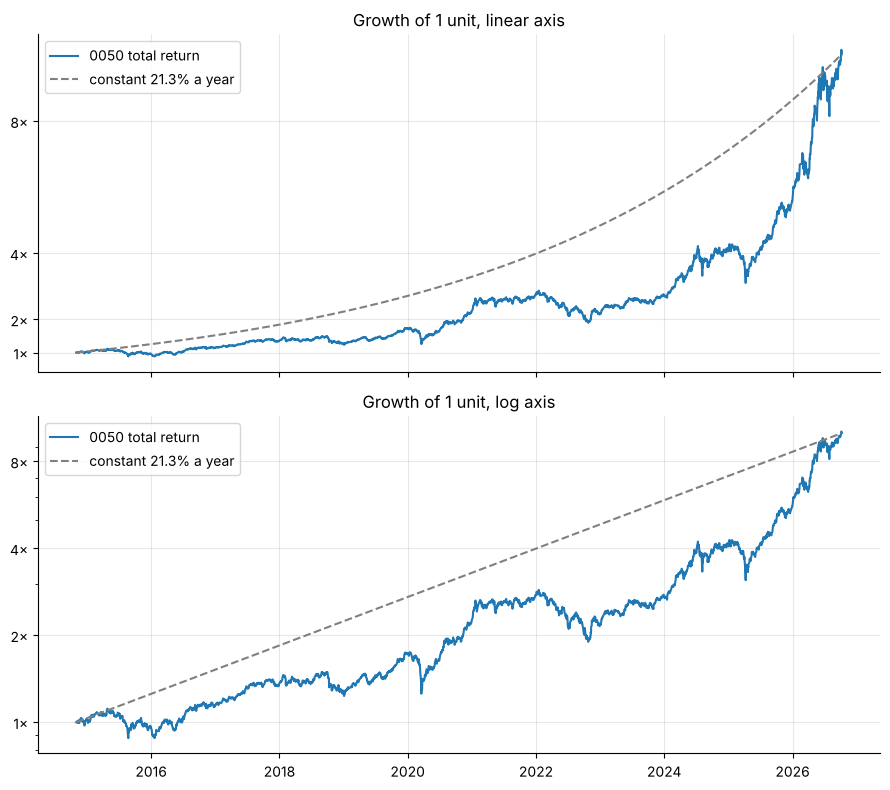

In [6]:
# Exhibit 3: linear and log axes, with the constant-rate path and doubling gridlines
t = np.array([(d - BASE).days / YEAR for d in dates]); path = G ** (t / tau)
fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True)
for ax, scale in zip(axes, ("linear", "log")):
    ax.plot(dates, W, label="0050 total return"); ax.plot(dates, path, "--", color="grey", label=f"constant {RG:.1%} a year")
    ax.set_yscale(scale); ax.set_yticks([1, 2, 4, 8]); ax.set_yticklabels(["1×", "2×", "4×", "8×"])
    ax.set_title(f"Growth of 1 unit, {scale} axis"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

## Part 3 — Compounding frequency and the number $e$

Periodic rate $i=r^{(n)}/n$; EAR $=(1+i)^n-1$ (eq. 1.4); continuous limit $e^r-1$ (eqs. 1.6–1.8).

In [7]:
FREQ = [("Annual", 1), ("Semiannual", 2), ("Quarterly", 4), ("Monthly", 12), ("Weekly", 52), ("Daily", 365)]
ear = pl.DataFrame({"compounding": [f for f, _ in FREQ] + ["Continuous"], "n": [n for _, n in FREQ] + [None]})
ear = ear.with_columns(
    pl.when(pl.col("n").is_null()).then(None).otherwise(pl.lit(0.15) / pl.col("n")).alias("periodic i at 15%"),
    pl.when(pl.col("n").is_null()).then(pl.lit(math.expm1(0.01725))).otherwise((1 + pl.lit(0.01725) / pl.col("n")) ** pl.col("n") - 1).alias("EAR at 1.725%"),
    pl.when(pl.col("n").is_null()).then(pl.lit(math.expm1(0.15))).otherwise((1 + pl.lit(0.15) / pl.col("n")) ** pl.col("n") - 1).alias("EAR at 15%"))
print("semiannual at 15% is exactly 1.075^2 - 1 = 0.155625, which rounds half up to 15.563%")
ear   # Exhibit 4

semiannual at 15% is exactly 1.075^2 - 1 = 0.155625, which rounds half up to 15.563%


compounding,n,periodic i at 15%,EAR at 1.725%,EAR at 15%
str,i64,f64,f64,f64
"""Annual""",1,0.150000,0.017250,0.150000
"""Semiannual""",2,0.075000,0.017324,0.155625
"""Quarterly""",4,0.037500,0.017362,0.158650
"""Monthly""",12,0.012500,0.017387,0.160755
"""Weekly""",52,0.002885,0.017397,0.161583
"""Daily""",365,0.000411,0.017399,0.161798
"""Continuous""",null,null,0.017400,0.161834


In [8]:
# Exhibit 5: Bernoulli's sequence, and the partial sums of 1/j!
bern = pl.DataFrame({"n": [1, 2, 4, 12, 52, 365, 8760, 525600]}).with_columns(
    ((1 + 1 / pl.col("n").cast(pl.Float64)) ** pl.col("n")).alias("(1+1/n)^n")).with_columns(
    (pl.lit(math.e) - pl.col("(1+1/n)^n")).alias("distance to e"))
print([round(sum(1 / math.factorial(j) for j in range(K + 1)), 6) for K in range(1, 7)])
bern

[2.0, 2.5, 2.666667, 2.708333, 2.716667, 2.718056]


n,(1+1/n)^n,distance to e
i64,f64,f64
1,2.000000,0.718282
2,2.250000,0.468282
4,2.441406,0.276876
12,2.613035,0.105247
52,2.692597,0.025685
365,2.714567,0.003714
8760,2.718127,0.000155
525600,2.718279,0.000003


整存整付: periodic i 0.14375%, EAR 1.7387%, interest NT$17,387;  存本取息: NT$17,250; difference NT$137
存本取息 monthly payments, actual/365 (31, 30, 28 days): [1465.07, 1417.81, 1323.29]
card: daily periodic rate i 0.041096%, simple NT$15,000, daily compounding 16.180% = NT$16,180, continuous 16.183%
stated daily-compounded rate that yields a 15% EAR: 13.979%
KC: EAR of 5.85% monthly 6.0094%; cc equivalents 5.8358% and 5.8269%


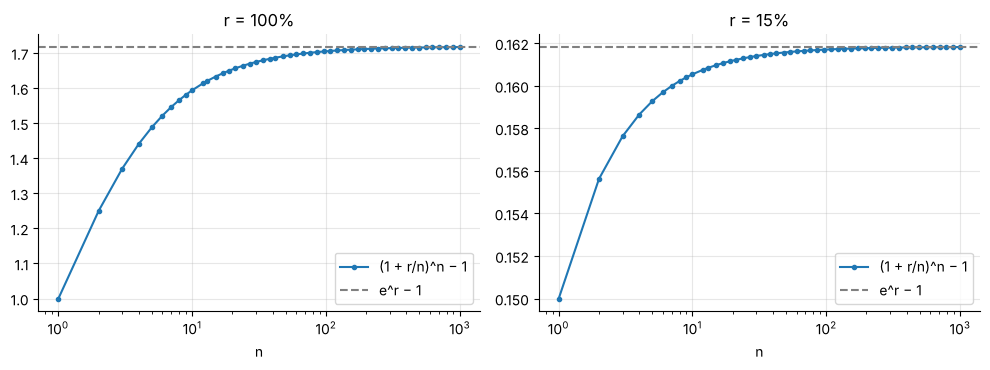

In [9]:
# Example 2 and Example 3, plus the Section 3 knowledge check
i_dep = 0.01725 / 12; dep = (1 + i_dep) ** 12 - 1
print(f"整存整付: periodic i {i_dep:.5%}, EAR {dep:.4%}, interest NT${1e6 * dep:,.0f};  存本取息: NT${1e6 * 0.01725:,.0f}; difference NT${1e6 * (dep - 0.01725):,.0f}")
print("存本取息 monthly payments, actual/365 (31, 30, 28 days):", [round(1e6 * 0.01725 * d / 365, 2) for d in (31, 30, 28)])
i_card = 0.15 / 365; card = (1 + i_card) ** 365 - 1
print(f"card: daily periodic rate i {i_card:.6%}, simple NT$15,000, daily compounding {card:.3%} = NT${1e5 * card:,.0f}, continuous {math.expm1(0.15):.3%}")
print(f"stated daily-compounded rate that yields a 15% EAR: {365 * (1.15 ** (1 / 365) - 1):.3%}")
print(f"KC: EAR of 5.85% monthly {(1 + 0.0585 / 12) ** 12 - 1:.4%}; cc equivalents {12 * math.log1p(0.0585 / 12):.4%} and {math.log(1.06):.4%}")

# convergence picture: EAR vs n at r = 100% and r = 15%
ns = np.unique(np.round(np.logspace(0, 3, 60)).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, r in zip(axes, (1.0, 0.15)):
    ax.semilogx(ns, (1 + r / ns) ** ns - 1, marker=".", label="(1 + r/n)^n − 1")
    ax.axhline(math.expm1(r), color="grey", ls="--", label="e^r − 1"); ax.set_title(f"r = {r:.0%}"); ax.set_xlabel("n"); ax.legend()
plt.tight_layout(); plt.show()

## Part 4 — Holding-period, annualized and continuously compounded returns

$R_G=G^{1/\tau}-1$ (1.9) and $g=\ln G/\tau=\ln(1+R_G)$ (1.10). Over $d$ calendar days $\tau=d/365.25$; over $T$ sessions $\tau=T/A$; then $R_G=(1+R)^{1/\tau}-1$ and $g=\ln(1+R)/\tau$ (1.11).

In [10]:
# Exhibit 6 values and Example 4 (the same growth quoted at several frequencies)
print(f"HPR {G - 1:.2%}  R_G {RG:.3%}  ln G {lnG:.4f}  g {g:.3%};  e^g - 1 = {math.expm1(g):.3%}")
for n in (1, 2, 4, 12, 52, 365):
    print(f"  stated rate compounded {n:>3}x a year with the same EAR: {n * ((1 + RG) ** (1 / n) - 1):.2%}")
print(f"  continuous: {math.log1p(RG):.2%}")

HPR 902.25%  R_G 21.298%  ln G 2.3048  g 19.308%;  e^g - 1 = 21.298%
  stated rate compounded   1x a year with the same EAR: 21.30%
  stated rate compounded   2x a year with the same EAR: 20.27%
  stated rate compounded   4x a year with the same EAR: 19.78%
  stated rate compounded  12x a year with the same EAR: 19.46%
  stated rate compounded  52x a year with the same EAR: 19.34%
  stated rate compounded 365x a year with the same EAR: 19.31%
  continuous: 19.31%


In [11]:
# Exhibit 7: trailing windows (start = last close on or before the same calendar date; tau = days / 365.25)
IDX = {d: k for k, d in enumerate(dates)}
def on_or_before(d):
    while d not in IDX:
        d = date.fromordinal(d.toordinal() - 1)
    return d
END = dates[-1]
rows = []
for label, nominal in [("3 months", date(2026, 7, 8)), ("6 months", date(2026, 4, 8)), ("1 year", date(2025, 10, 8)),
                       ("3 years", date(2023, 10, 8)), ("5 years", date(2021, 10, 8)), ("10 years", date(2016, 10, 8)),
                       ("Since 31 Oct 2014", BASE)]:
    s = on_or_before(nominal); Gw = W[IDX[END]] / W[IDX[s]]; tw = (END - s).days / YEAR
    rows.append({"window": label, "from": s, "days": (END - s).days, "tau": tw, "HPR": Gw - 1,
                 "annualized": Gw ** (1 / tw) - 1, "cont. comp.": math.log(Gw) / tw})
pl.DataFrame(rows)

window,from,days,tau,HPR,annualized,cont. comp.
str,date,i64,f64,f64,f64,f64
"""3 months""",2026-07-08,92,0.251882,0.090268,0.409323,0.343109
"""6 months""",2026-04-08,183,0.501027,0.459885,1.127961,0.755164
"""1 year""",2025-10-08,365,0.999316,0.917142,0.917997,0.651281
"""3 years""",2023-10-06,1098,3.006160,2.968601,0.581747,0.458530
"""5 years""",2021-10-08,1826,4.999316,2.950460,0.316273,0.274804
"""10 years""",2016-10-07,3653,10.001369,7.751978,0.242218,0.216898
"""Since 31 Oct 2014""",2014-10-31,4360,11.937029,9.022465,0.212983,0.193082


In [12]:
# Example 5: a 90-day return annualized five ways
a90, b90 = date(2026, 7, 9), date(2026, 10, 7)
G90 = W[IDX[b90]] / W[IDX[a90]]; T90 = IDX[b90] - IDX[a90]; d90 = (b90 - a90).days
print(f"{d90} days, T = {T90} sessions, HPR {G90 - 1:.4%}")
print(f"calendar {G90 ** (YEAR / d90) - 1:.2%} (with 365: {G90 ** (365 / d90) - 1:.2%}) | A=252 {G90 ** (252 / T90) - 1:.2%} | "
      f"A=243.8 {G90 ** (243.8 / T90) - 1:.2%} | cont. {math.log(G90) * YEAR / d90:.2%} | simple {(G90 - 1) * YEAR / d90:.2%}")

# TWSE sessions per year: days on which 0050 or 00631L traded
u = (pl.concat([pl.read_csv(DATA / "0050_daily_raw.csv").select("date"), pl.read_csv(DATA / "00631L_daily_raw.csv").select("date")])
       .unique().with_columns(pl.col("date").str.to_date()).sort("date"))
per_year = (u.with_columns(pl.col("date").dt.year().alias("year")).filter(pl.col("year").is_between(2015, 2025))
             .group_by("year").len().sort("year"))
print("TWSE sessions 2015-2025:", per_year["len"].to_list(), "mean", round(per_year["len"].mean(), 1))

90 days, T = 61 sessions, HPR 10.3302%
calendar 49.03% (with 365: 48.99%) | A=252 50.10% | A=243.8 48.13% | cont. 39.90% | simple 41.92%
TWSE sessions 2015-2025: [244, 244, 246, 247, 242, 245, 244, 246, 239, 242, 243] mean 243.8


In [13]:
# Example 6: mean daily log return x 252 vs x the sample's own A = T / tau
lr = np.log1p(R); T = len(R); A = T / tau
print(f"T = {T} returns, mean {lr.mean():.6%}; x252 = {lr.mean() * 252:.2%} (EAR {math.expm1(lr.mean() * 252):.2%}); "
      f"A = T/tau = {A:.1f}; x A = {lr.mean() * A:.2%} (= g)")
twse = u.filter((pl.col("date") > pl.lit(BASE)) & (pl.col("date") <= pl.lit(END))).height
own_dates = set(own["date"]); al_dates = set(aligned["date"])
print(f"exchange sessions in the window {twse} ({twse / tau:.1f} a year); 0050's own {own.height}; aligned {T}")
print("sessions on which 0050 did not trade:", sorted(str(d) for d in set(u["date"]) - own_dates - {BASE} if BASE < d <= END))
print("0050 sessions folded into the next aligned return (00631L did not trade):", sorted(str(d) for d in own_dates - al_dates))

T = 2902 returns, mean 0.079422%; x252 = 20.01% (EAR 22.16%); A = T/tau = 243.1; x A = 19.31% (= g)
exchange sessions in the window 2911 (243.9 a year); 0050's own 2906; aligned 2902
sessions on which 0050 did not trade: ['2025-06-11', '2025-06-12', '2025-06-13', '2025-06-16', '2025-06-17']
0050 sessions folded into the next aligned return (00631L did not trade): ['2026-03-25', '2026-03-26', '2026-03-27', '2026-03-30']


## Part 5 — Aggregation across time, positions and currencies

Across time $\ln G=\sum_t r_t$ (1.12); across $J$ positions $R_p=\sum_jw_jR_j$ (1.13), and for long-only weights ($w_j\ge0$, $\sum_jw_j=1$) $r_p\ge\sum_jw_jr_j$ (1.14); across factors $r^{\text{TWD}}=r^{\text{USD}}+r^{\text{FX}}$ (1.15).

In [14]:
# Exhibit 8: two-year blocks
bounds = [BASE] + [on_or_before(date(y, 10, 31)) for y in (2016, 2018, 2020, 2022, 2024)] + [END]
blocks = pl.DataFrame([{"start": a, "end": b, "days": (b - a).days, "R": W[IDX[b]] / W[IDX[a]] - 1,
                        "r": math.log(W[IDX[b]] / W[IDX[a]])} for a, b in zip(bounds[:-1], bounds[1:])])
print("sum of r:", round(blocks["r"].sum(), 6), " ln G:", round(lnG, 6), " sum of printed r (4 dp):", round(blocks["r"].round(4).sum(), 4))
print("sum of printed simple returns (2 dp, %):", round((blocks["R"] * 100).round(2).sum(), 2))
blocks

sum of r: 2.304829  ln G: 2.304829  sum of printed r (4 dp): 2.3048
sum of printed simple returns (2 dp, %): 332.08


start,end,days,R,r
date,date,i64,f64,f64
2014-10-31,2016-10-31,731,0.160349,0.148721
2016-10-31,2018-10-31,730,0.140628,0.131579
2018-10-31,2020-10-30,730,0.435611,0.361590
2020-10-30,2022-10-31,731,0.023495,0.023224
2022-10-31,2024-10-30,730,1.064731,0.725000
2024-10-30,2026-10-08,708,1.496064,0.914715


In [15]:
# Example 7: 50/50 buy-and-hold of 0050 and 00631L, correct vs averaged log returns
GL = WL[-1]; Gp = 0.5 * G + 0.5 * GL; avg = 0.5 * lnG + 0.5 * math.log(GL)
print(f"00631L G {GL:.4f} (ln {math.log(GL):.4f}); portfolio G {Gp:.2f} = +{Gp - 1:.0%}; ln {math.log(Gp):.3f}")
print(f"average log {avg:.4f} -> e^avg {math.exp(avg):.2f} = +{math.exp(avg) - 1:.0%} (= sqrt(G*GL) {math.sqrt(G * GL):.2f}); "
      f"understatement {(Gp - math.exp(avg)) * 100:.0f} pp")

# (1.14) needs long-only weights: a short position can reverse it
w, r = np.array([1.5, -0.5]), np.array([0.10, 0.20])
print(f"short counterexample: r_p = ln(sum w e^r) = {math.log(w @ np.exp(r)):.4f} < sum w r = {w @ r:.4f}")

# Example 8: a USD asset seen from Taiwan (hypothetical numbers)
Rusd, Rfx = 0.20, 29.6 / 32.0 - 1
print(f"FX {Rfx:.2%}; exact {(1 + Rusd) * (1 + Rfx) - 1:.2%}; logs {math.log1p(Rusd):.5f} + {math.log1p(Rfx):.5f} = {math.log1p(Rusd) + math.log1p(Rfx):.5f}; "
      f"naive {Rusd + Rfx:.2%}; cross term {Rusd * Rfx:.2%}")
print(f"KC: log returns +0.1/-0.1 -> simple {math.expm1(0.1):.2%}, {math.expm1(-0.1):.2%}; portfolio {0.5 * math.expm1(0.1) + 0.5 * math.expm1(-0.1):.2%}")

00631L G 44.5446 (ln 3.7965); portfolio G 27.28 = +2628%; ln 3.306
average log 3.0507 -> e^avg 21.13 = +2013% (= sqrt(G*GL) 21.13); understatement 615 pp
short counterexample: r_p = ln(sum w e^r) = 0.0460 < sum w r = 0.0500
FX -7.50%; exact 11.00%; logs 0.18232 + -0.07796 = 0.10436; naive 12.50%; cross term -1.50%
KC: log returns +0.1/-0.1 -> simple 10.52%, -9.52%; portfolio 0.50%


## Part 6 — Growth equations, doubling, drawdowns and recovery

$\tau=\ln(W_\tau/W_0)/\ln(1+R)$ and $R=(W_\tau/W_0)^{1/\tau}-1$ (1.16); drawdown $\mathrm{DD}_t=1-W_t/\max(W_0,\dots,W_t)$, recovery gain $\mathrm{DD}/(1-\mathrm{DD})$ (1.17) and log distance $-\ln(1-\mathrm{DD})$.

In [16]:
# Exhibit 9: doubling times
pl.DataFrame({"R": [0.01725, 0.04, 0.08, 0.15, RG]}).with_columns(
    (pl.lit(math.log(2)) / pl.col("R").log1p()).alias("exact tau_2"), (72 / (100 * pl.col("R"))).alias("rule of 72"))

R,exact tau_2,rule of 72
f64,f64,f64
0.017250,40.528031,41.739130
0.040000,17.672988,18.000000
0.080000,9.006468,9.000000
0.150000,4.959484,4.800000
0.212983,3.589905,3.380558


In [17]:
# Example 9: retirement target
goal = 20 / 3
print(f"required R {goal ** (1 / 25) - 1:.2%}, g {math.log(goal) / 25:.2%}; time at 6%: {math.log(goal) / math.log(1.06):.2f} years; "
      f"wealth at 60: NT${3e6 * 1.06 ** 25:,.0f}")
print(f"nominal with 2% inflation: {math.expm1(math.log(goal) / 25 + math.log(1.02)):.2%} = {(goal ** (1 / 25)) * 1.02 - 1:.2%}")

# Exhibit 10: recovery arithmetic
rec = pl.DataFrame({"DD": [0.10, 0.20, 0.25, 1 / 3, 0.50, 0.75, 0.90]})
rec.with_columns((pl.col("DD") / (1 - pl.col("DD"))).alias("gain needed"), (-(1 - pl.col("DD")).log()).alias("log distance")).with_columns(
    (pl.col("log distance") / math.log(1.08)).alias("years at 8%"), (pl.col("log distance") / g).alias("years at R_G"))

required R 7.88%, g 7.59%; time at 6%: 32.56 years; wealth at 60: NT$12,875,612
nominal with 2% inflation: 10.04% = 10.04%


DD,gain needed,log distance,years at 8%,years at R_G
f64,f64,f64,f64,f64
0.100000,0.111111,0.105361,1.369011,0.545677
0.200000,0.250000,0.223144,2.899435,1.155691
0.250000,0.333333,0.287682,3.738022,1.489945
0.333333,0.500000,0.405465,5.268446,2.099960
0.500000,1.000000,0.693147,9.006468,3.589905
0.750000,3.000000,1.386294,18.012937,7.179811
0.900000,9.000000,2.302585,29.918840,11.925407


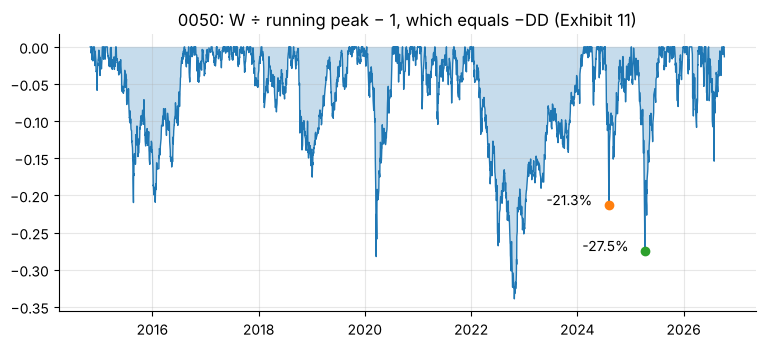

peak,trough,DD at trough,gain needed,recovered,days to recover,sessions,days at g
date,date,f64,f64,date,i64,i64,i64
2015-04-27,2015-08-24,0.209622,0.265217,2016-08-08,350,234,445
2018-08-30,2019-01-04,0.175328,0.212604,2019-09-16,255,166,365
2020-01-14,2020-03-19,0.282352,0.393441,2020-07-13,116,77,628
2022-01-17,2022-10-25,0.339292,0.513528,2024-02-15,478,313,784
2024-07-11,2024-08-05,0.213038,0.270710,2025-01-06,154,104,453
2025-01-07,2025-04-09,0.274898,0.379116,2025-07-17,99,64,608
2026-06-22,2026-07-30,0.153870,0.181852,2026-09-21,53,37,316


In [18]:
# Exhibit 11 and Exhibit 12: drawdown curve and episodes deeper than 15%
DD = 1 - W / np.maximum.accumulate(W)          # the running peak includes W_0 = 1; DD is a positive number
episodes, in_dd = [], False
for k in range(1, len(W)):
    if DD[k] > 0 and not in_dd:
        in_dd, s0 = True, k - 1
    if in_dd and DD[k] <= 0:
        tr = s0 + int(np.argmax(DD[s0:k])); in_dd = False
        if DD[tr] >= 0.15:
            depth = DD[tr]
            episodes.append({"peak": dates[s0], "trough": dates[tr], "DD at trough": depth, "gain needed": depth / (1 - depth), "recovered": dates[k],
                             "days to recover": (dates[k] - dates[tr]).days, "sessions": k - tr,
                             "days at g": round(-math.log1p(-depth) / g * YEAR)})
ep = pl.DataFrame(episodes)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.fill_between(dates, -DD, 0, alpha=0.25); ax.plot(dates, -DD, lw=1)
for d0 in (date(2024, 8, 5), date(2025, 4, 9)):
    y0 = -DD[dates.index(d0)]
    ax.plot(d0, y0, "o"); ax.annotate(f"{y0:.1%}", (d0, y0), xytext=(-45, 0), textcoords="offset points")
ax.set_title("0050: W ÷ running peak − 1, which equals −DD (Exhibit 11)"); plt.show()
ep   # Exhibit 12

In [19]:
# Example 10: the 2024 and 2025 episodes
for d0 in ("2024-08-02", "2024-08-05", "2025-04-02", "2025-04-07", "2025-04-08", "2025-04-09", "2025-04-10"):
    i = IDX[date.fromisoformat(d0)]
    print(d0, f"R {W[i] / W[i - 1] - 1:+.2%}  DD {DD[i]:.2%}")
i7, i9 = IDX[date(2025, 4, 7)], IDX[date(2025, 4, 9)]
print(f"log split: {math.log1p(-DD[i7 - 1]):.4f} + {math.log(W[i9] / W[i7 - 1]):.4f} = {math.log1p(-DD[i9]):.4f};  "
      f"at g: {-math.log1p(-DD[i9]) / g:.2f} years vs actual {99 / YEAR:.2f}")

2024-08-02 R -5.05%  DD 13.40%
2024-08-05 R -9.13%  DD 21.30%
2025-04-02 R -0.17%  DD 12.71%
2025-04-07 R -10.00%  DD 21.44%
2025-04-08 R -3.25%  DD 23.99%
2025-04-09 R -4.60%  DD 27.49%
2025-04-10 R +9.99%  DD 20.25%
log split: -0.1359 + -0.1855 = -0.3214;  at g: 1.66 years vs actual 0.27


## Part 7 — Practice-problem solutions (computational) and an extension

In [20]:
L2 = math.log(2)
print("PP1 ", f"log2(25) = {math.log(25) / L2:.2f}  | ln25/log10(2) = {math.log(25) / math.log10(2):.2f}  | 25/2 = {25 / 2:.2f}")
print("PP2 ", f"{(1.01) ** 12 - 1:.2%}  (continuous {math.expm1(0.12):.2%})")
ear3 = 1.006 ** 4 - 1
print("PP3 ", f"EAR {ear3:.4%}  r(12) {12 * ((1 + ear3) ** (1 / 12) - 1):.4%}  cc {math.log1p(ear3):.4%}")
print("PP4 ", f"{math.expm1(0.08):.2%}  (wrong direction {math.log(1.08):.2%})")
print("PP6 ", f"price-only annualized {G_price ** (1 / tau) - 1:.2%}  g_P {math.log(G_price) / tau:.2%}  dividends {div_log / tau:.2%}")
print("PP7 ", f"{1.06 ** 3 - 1:.2%}  | 4 x 6% = {4 * 0.06:.2%}  | 1.06^4 - 1 = {1.06 ** 4 - 1:.2%}")
yr = [0.2740, 0.4867, 0.3685]; G3 = np.prod([1 + v for v in yr])
print("PP8 ", f"cum {G3 - 1:.2%}  ann {G3 ** (1 / 3) - 1:.2%}  logs {[round(math.log1p(v), 5) for v in yr]} sum {sum(math.log1p(v) for v in yr):.5f}  "
      f"cc {math.log(G3) / 3:.2%}  sum simple {sum(yr):.2%}")
pp9 = 0.5 * (math.exp(0.3) + math.exp(-0.1))
print("PP9 ", f"r_p {math.log(pp9):.2%}  | average log {0.5 * 0.3 + 0.5 * -0.1:.1%}  | e^0.10 - 1 = {math.expm1(0.1):.1%}")
print("PP10", f"{1.04 * 1.05 - 1:.2%}  logs {math.log(1.04) + math.log(1.05):.5f}")
print("PP11", f"{math.log(4) / math.log(1.06):.2f}  {math.log(4) / 0.06:.2f}")
print("PP12", f"{5 ** (1 / 15) - 1:.2%}  (cc {math.log(5) / 15:.2%}; simple {4 / 15:.2%})")
print("PP13", f"{0.35 / 0.65:.2%}  {-math.log(0.65) / math.log(1.10):.2f} years  DD after +30%: {1 - 0.65 * 1.3:.2%}")
print("PP14", f"{0.33929 / 0.66071:.2%}  {-math.log(0.66071):.4f}  {-math.log(0.66071) / 0.19308:.3f} years = {-math.log(0.66071) / 0.19308 * YEAR:.0f} days")

PP1  log2(25) = 4.64  | ln25/log10(2) = 10.69  | 25/2 = 12.50
PP2  12.68%  (continuous 12.75%)
PP3  EAR 2.4217%  r(12) 2.3952%  cc 2.3928%
PP4  8.33%  (wrong direction 7.70%)
PP6  price-only annualized 17.76%  g_P 16.35%  dividends 2.96%
PP7  19.10%  | 4 x 6% = 24.00%  | 1.06^4 - 1 = 26.25%
PP8  cum 159.20%  ann 37.37%  logs [0.24216, 0.39656, 0.31372] sum 0.95244  cc 31.75%  sum simple 112.92%
PP9  r_p 11.99%  | average log 10.0%  | e^0.10 - 1 = 10.5%
PP10 9.20%  logs 0.08801
PP11 23.79  23.10
PP12 11.33%  (cc 10.73%; simple 26.67%)
PP13 53.85%  4.52 years  DD after +30%: 15.50%
PP14 51.35%  0.4144  2.146 years = 784 days


In [21]:
# PP15: ten calendar years 2015-2024
a, b = date(2014, 12, 31), date(2024, 12, 31)
G10 = W[IDX[b]] / W[IDX[a]]; tau10 = (b - a).days / YEAR
m = (pl.col("date") > pl.lit(a)) & (pl.col("date") <= pl.lit(b))
sub = aligned.filter(m)["R_0050"].log1p()
T10, mu = sub.len(), sub.mean(); A10 = T10 / tau10
print(f"tau = {(b - a).days}/365.25 = {tau10:.4f}  G {G10:.4f}  R_G {G10 ** (1 / tau10) - 1:.2%}  g {math.log(G10) / tau10:.2%}")
print(f"T = {T10} returns, A = T/tau = {A10:.1f}, mean daily log {mu:.6%}; x252 {mu * 252:.2%} (EAR {math.expm1(mu * 252):.2%}); "
      f"x A {mu * A10:.2%} (EAR {math.expm1(mu * A10):.2%})")

tau = 3653/365.25 = 10.0014  G 4.0030  R_G 14.88%  g 13.87%
T = 2439 returns, A = T/tau = 243.9, mean daily log 0.056869%; x252 14.33% (EAR 15.41%); x A 13.87% (EAR 14.88%)


### Extension: drawdowns of a leveraged fund

Repeat Exhibit 12 for 00631L, the daily 2× fund (series `WL` above). For its 2025 drawdown, compute the depth, the gain needed and the log distance, and compare the log distance with twice 0050's (0.3214). Why is the leveraged fund's log loss *more* than twice the index's in a crash, and what does that imply for its recovery time at a given growth rate? The variance-drag decomposition of LM3 gives the answer. A starting point:

In [22]:
DDL = 1 - WL / np.maximum.accumulate(WL)
in2025 = np.array([date(2025, 1, 1) <= d <= date(2025, 6, 30) for d in dates])
k = int(np.argmax(np.where(in2025, DDL, 0.0)))
print(f"00631L 2025 trough {dates[k]}: DD {DDL[k]:.2%}, gain needed {DDL[k] / (1 - DDL[k]):.2%}, "
      f"log distance {-math.log1p(-DDL[k]):.4f} vs 2 x 0050's {2 * -math.log1p(-DD[IDX[date(2025, 4, 9)]]):.4f}")

00631L 2025 trough 2025-04-09: DD 55.14%, gain needed 122.93%, log distance 0.8017 vs 2 x 0050's 0.6429
